In [79]:
import pandas as pd
import numpy as np

In [80]:
df = pd.read_csv("powerplant_data.csv")

In [81]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [82]:
#AT - temp, #V = Vaccuum, #Ap = Pressure, #Rh = Humidity,  #PE- Prduced Energy

In [83]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [84]:
X = df.drop("PE",axis =1) #separating the X and y cols
y = df["PE"]

In [85]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [86]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state =42)

In [87]:
X_train

,AT,V,AP,RH
5487,25.24,63.47,1011.30,66.21
3522,26.09,70.40,1007.41,85.37
6916,26.63,73.68,1015.15,85.13
7544,32.06,71.85,1007.90,56.44
7600,28.70,71.64,1007.11,69.85
...,...,...,...,...
5734,26.25,61.02,1011.47,71.22
5191,29.17,64.79,1016.43,61.05
5390,18.00,43.70,1015.40,61.28
860,26.73,68.84,1010.75,66.83


In [88]:
df.shape

(9568, 5)

In [89]:
from sklearn.preprocessing import StandardScaler  #Scaling the data to normalise the data values 

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [90]:
X_test_scaled 

array([[ 1.36255441,  0.24305848, -1.27798491, -1.04586379],
       [ 0.82147733,  1.36986442, -0.74695303,  0.31071896],
       [-0.247116  , -0.73708132,  1.92304887, -0.14668594],
       ...,
       [-0.67970645, -1.15815506, -0.31652036, -0.05697206],
       [ 1.33136451,  1.34463153, -0.87558808, -0.39000089],
       [-0.26474508, -0.26711887,  0.33984824,  1.14397069]],
      shape=(1914, 4))

In [91]:
import torch
import torch.nn as nn

In [92]:
X_train_tensor = torch.tensor(X_train_scaled, dtype = torch.float32) #float32 represents the data-type of the data in X_train_tensor
y_train_tensor = torch.tensor(y_train.values, dtype = torch.float32).view(-1,1)

X_test_tensor = torch.tensor(X_test_scaled, dtype = torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

In [93]:
type(X_train_scaled)

numpy.ndarray

In [94]:
type(y_train) #since its a series of Pandas we use .values here to access the values of the given series

pandas.Series

In [95]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [96]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

Deep Learning Architecture

In [97]:
#Building the ANN Regression Model

class ANN(nn.Module):
    def __init__(self): #creating constructor ( work is to call the super constructor i.e the constructor of nn.Module )
        super(ANN, self).__init__()# constructor from nn.Module

        self.model = nn.Sequential(
            #1st Hidden Layer
            nn.Linear(X_train.shape[1],6), #nn.Linear(input_features, output_features)
            nn.ReLU(),
    
            #2nd Hidden Layer
            nn.Linear(6,6), #nn.Linear(input_features, output_features)
            nn.ReLU(),
    
            #o/p Layer
            nn.Linear(6,1),
            
        )
    #Forward Propagation
    def forward(self,x):
        return self.model(x)
        
        

In [98]:
import torch.optim as optim

model = ANN() #creating an obj of ANN Class
criterion = nn.MSELoss() #loss fnc as regression we take MSE
optimiser = optim.Adam(model.parameters())#ADAM Optimiser imported from Pytorch

Training the ANN Model

In [99]:
train_losses = []
epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # total training loss for 1 epoch

    for xb, yb in train_loader: #xb - input features of each batch, yb- o/p features of each batch , train_loaders has all the batches
        optimiser.zero_grad() # as the loss val gets accumulated to prevent it we do remove the old gradients
        
        outputs = model(xb) #predicted o/p for each batch
        loss = criterion(outputs,yb)#cal loss for a batch
        loss.backward() #compute the gd for back prop automatically by this function
        optimiser.step() #params updated by optimiser optimising the model
        
        running_loss += loss.item() # loss is a tensor => py float

    #this is repeated for all batches under 1 epoch
    #this is done for full 100 epochs
    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)
        
        

Validation for the model on base of testing data at each step

In [113]:
# Validation- from training mode to validation loss 
#Here we are validating each step after training on the test data
val_losses = []
model.eval()
running_val_loss = 0.0
best_val_loss = float("inf")

with torch.no_grad(): # no gradients compute here only validation is going on 
    for xb, yb in test_loader:
        outputs = model(xb)
        loss = criterion(outputs, yb)
        running_val_loss += loss
epoch_val_loss = running_val_loss / len(test_loader)
val_losses.append(epoch_val_loss)
print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")
#here the training loss will decrease and become stable at a point and the validatn loss is also decreasing which shows that the model is learning
if epoch_val_loss < best_val_loss:#best testing loss
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") #.pt or .pth


epoch 100/100 ==> train loss = 21.076983873049418 & val loss = 19.077070236206055


Train length: 100 | Val length: 1
Val first 5: [19.077070236206055]
Val has NaN: False


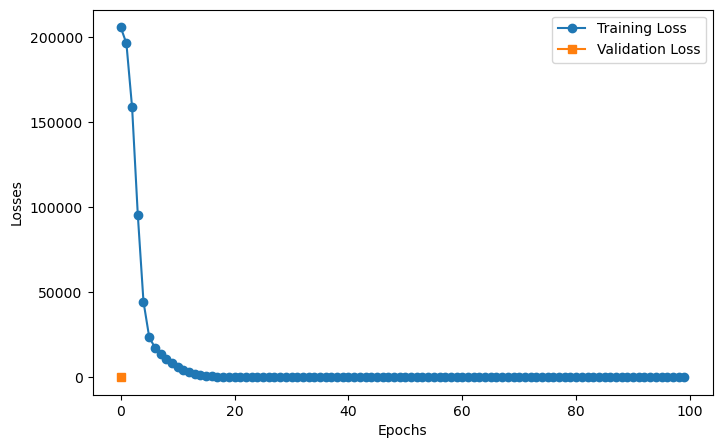

In [114]:
import numpy as np
import matplotlib.pyplot as plt

def to_floats(values):
    out = []
    for v in values:
        if hasattr(v, "detach"):
            v = v.detach().cpu().item()
        elif hasattr(v, "item"):
            v = v.item()
        out.append(float(v))
    return out

train_clean = to_floats(train_losses)
val_clean = to_floats(val_losses)

print("Train length:", len(train_clean), "| Val length:", len(val_clean))
print("Val first 5:", val_clean[:5])
print("Val has NaN:", any(np.isnan(val_clean)))

n_train, n_val = len(train_clean), len(val_clean)

# Spread validation points evenly across the training epochs
if n_val == n_train:
    val_x = np.arange(n_val)
elif n_val > 0:
    val_x = np.linspace(0, n_train - 1, n_val)
else:
    val_x = []

plt.figure(figsize=(8, 5))
plt.plot(np.arange(n_train), train_clean, label="Training Loss", marker="o")
if n_val > 0:
    plt.plot(val_x, val_clean, label="Validation Loss", marker="s")
else:
    print("WARNING: val_losses is empty, so nothing to plot.")
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()
plt.show()

In [115]:
# Loading the best model
model.load_state_dict(torch.load("best_model.pt")) #loads the best values of the model

<All keys matched successfully>

In [117]:
# Evaluation

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds, y_train_tensor)
    test_mse_loss = criterion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())#trainning loss
print("Testing MSE:", test_mse_loss.item())#testing loss

Training MSE: 20.766101837158203
Testing MSE: 19.082576751708984


In [118]:
from sklearn.metrics import r2_score

print("r^2 score =", r2_score(y_test, test_preds))

r^2 score = 0.9333113199196391


In [119]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.163422,433.27
1,436.994446,438.16
2,461.749481,458.42
3,476.819092,480.82
4,435.518066,441.41
...,...,...
1909,451.428772,456.70
1910,431.611237,438.04
1911,467.695953,467.80
1912,431.078674,437.14
